In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import datetime
import glob
import joblib
import shutil
import umap

sys.path.insert(0, "cellular_cycle") # add path to the model

from cell_cycle_death_model import model
from model_fxns import minmax_scale, stack_sliding_window

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
SAVE_DIR.mkdir(exist_ok=True)

OVERWRITE = True # Overwrite existing simulation files
SET_JPARAM = False # Set the parameter values for the simulation using PSO-optimized values

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

ORIG_SIM_DIR = Path(SAVE_DIR,'orig_sims')
USE_ORIGINAL = True # set to true to automatically download the original data from Dropbox
GENERATE_UMAP = True # Generate UMAP plots for the simulation output

output_from = 4 # 1: original 3: 03_ECM_model_output.ipynb 4: 04_Stoch_sims_for_UMAP.ipynb

sys_type = sys.platform

c:\Users\tysondr\AppData\Local\mambaforge\envs\ECM_model\lib\site-packages\umap\distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
c:\Users\tysondr\AppData\Local\mambaforge\envs\ECM_model\lib\site-packages\umap\distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
c:\Users\tysondr\AppData\Local\mambaforge\envs\E

### Detect computer system
NOTE: UMAP reducer files are dependent on processor, OS and package versions

### Load Data

These files were generated using original parameters and used to produce UMAP for the manuscript (
    
**Output files from [03_ECM_model_output.ipynb](03_ECM_model_output.ipynb)**:  
```
[PosixPath('/Users/darren/ECM_mod_output/stoch_sim_soft_DMSO_param_cycdi_0_0.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_soft_erl_param_cycdi_0_0.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_int_DMSO_param_cycdi_0_0.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_int_erl_param_cycdi_0_0.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_stiff_DMSO_param_cycdi_0_0.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_stiff_erl_param_cycdi_0_0.csv')]
 ```

**Output files from [04_Stoch_sims_for_UMAP.ipynb](04_Stoch_sims_for_UMAP.ipynb)**:
```
ODE_sim_DMSO_stiff_000_orig.csv
ODE_sim_DMSO_stiff_029_orig.csv
ODE_sim_DMSO_stiff_049_orig.csv
ODE_sim_DMSO_stiff_074_orig.csv
ODE_sim_DMSO_stiff_099_orig.csv
ODE_sim_ERL_stiff_000_orig.csv
ODE_sim_ERL_stiff_029_orig.csv
ODE_sim_ERL_stiff_049_orig.csv
ODE_sim_ERL_stiff_074_orig.csv
ODE_sim_ERL_stiff_099_orig.csv
stoch_sim_DMSO_stiff_000_orig.csv
stoch_sim_DMSO_stiff_029_orig.csv
stoch_sim_DMSO_stiff_049_orig.csv
stoch_sim_DMSO_stiff_074_orig.csv
stoch_sim_DMSO_stiff_099_orig.csv
stoch_sim_ERL_stiff_000_orig.csv
stoch_sim_ERL_stiff_029_orig.csv
stoch_sim_ERL_stiff_049_orig.csv
stoch_sim_ERL_stiff_074_orig.csv
stoch_sim_ERL_stiff_099_orig.csv
```

#### NOTE: Variations in UMAP output will exist due to use of different stochastic simulations or generation on different platforms


In [2]:
if USE_ORIGINAL and not ORIG_SIM_DIR.exists():
    print('Downloading original stochastic simulation data')
    if sys_type == 'win32':
        new_url = 'https://www.dropbox.com/scl/fi/j4c3d2ypdws50lks45lag/orig_sims.zip?rlkey=evill8yurm6dzq7dnf03036vf&dl=1'
        !curl -L -o orig_stoch_sims.zip $new_url
        !unzip orig_stoch_sims.zip
        !mv orig_sims $ORIG_SIM_DIR
        os.remove('orig_stoch_sims.zip')
        os.remove('_MACOSX', recursive=True)
    else:
        !wget 'https://www.dropbox.com/scl/fi/dn1mja4obyp7bw0ac8xna/stochastic_simulations.zip?rlkey=vx67yyrgtttzytq26yb26z7uw&dl=1' -O orig_stoch_sims.zip
        !unzip orig_stoch_sims.zip
        !mv stochastic_simulations $ORIG_SIM_DIR
        os.remove('orig_stoch_sims.zip')

In [3]:
exp_stiff_vals = ['000','049','099']

In [4]:
if SET_JPARAM:
    stoch_filenames_03 = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_psoparam_cycdi_0_0' in f]
    stoch_filenames_03.sort()
    stoch_filenames_04 = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_stiff_' in f]
    stoch_filenames_04.sort()
else:
    stoch_filenames_03 = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_param_cycdi_0_0' in f]
    stoch_filenames_03.sort()
    stoch_filenames_04 = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_stiff_' in f and 'orig' in f]
    stoch_filenames_04.sort()

if USE_ORIGINAL:
    stoch_filenames = [str(Path(ORIG_SIM_DIR, f)) for f in os.listdir(ORIG_SIM_DIR) if '.csv' in f and 'stoch_sim' in f]
else:
    stoch_filenames = globals()[f'stoch_filenames_0{output_from}']

stoch_filenames.sort()
stoch_filenames

['C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_000_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_029_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_049_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_074_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_099_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_000_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_029_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_049_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_074_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_099_orig.csv']

In [5]:
stoch_filenames_umap = [f for f in stoch_filenames if any([x in str(f) for x in exp_stiff_vals])]
stoch_filenames_umap

['C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_000_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_049_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_099_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_000_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_049_orig.csv',
 'C:\\Users\\tysondr\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_099_orig.csv']

In [6]:
ode_filenames = [Path(str(f).replace('stoch_sim','ODE_sim')) for f in stoch_filenames]
ode_filenames

[WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_029_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_074_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_029_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_074_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_099_orig.csv')]

In [7]:
ode_filenames_umap = [Path(str(f).replace('stoch_sim','ODE_sim')) for f in stoch_filenames_umap]
ode_filenames_umap

[WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/tysondr/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_099_orig.csv')]

### Set UMAP parameters

In [8]:
# Important params to set the window size and step time distance
init_dt = 0.1                 # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.01

# set the random state for reproducibility; set to None to get different results each time
RANDOM_STATE = 5

### Define UMAP reducer filename

In [9]:
if sys_type == 'darwin':
    sys_name = 'mac'
    r_path_date = '20240502'
    r_dbpath = 'https://www.dropbox.com/scl/fi/ovk8v5fc9rvsbm43zww8h/reducer_20240502_0.1_0.1_4_0.5.sav?rlkey=jb9om518rtjth0q9bs6mdjj79&dl=1'
if sys_type == 'win32': 
    sys_name = 'win'
    r_path_date = '03_20'
    r_dbpath = 'https://www.dropbox.com/scl/fi/jlfya4m3bhp9akr3hzco2/reducer_03_20_0.1_0.1_4_0.5.sav?rlkey=3z8ozy95khsjdqplkg8ce11md&dl=1'
if sys_type == 'linux': 
    sys_name = 'linux'
    r_path_date = '20240606'
    r_dbpath = "https://www.dropbox.com/scl/fi/79lp5174wny1ngiy4w1h7/reducer_20240606_0.1_0.1_4_0.5.sav?rlkey=3p1xkbzkdmwy9ivmn5r64xtlh&dl=1"

#reducer save name
if SET_JPARAM:
    r_name = f'reducer_psoparams_{sys_name}_{init_dt}_{dt}_{window}_{time_step}.sav'
else:
    r_name = f'reducer_{sys_name}_{init_dt}_{dt}_{window}_{time_step}.sav'

In [10]:
if not GENERATE_UMAP:
    r_path = Path(SAVE_DIR,'UMAP',r_name.replace(f'{sys_name}',r_path_date))
else:
    r_path = Path(SAVE_DIR,'UMAP',r_name)

%env R_PATH = {r_path}
%env R_DBPATH = {r_dbpath}

env: R_PATH=C:\Users\tysondr\ECM_mod_output\UMAP\reducer_win_0.1_0.1_4_0.5.sav
env: R_DBPATH=https://www.dropbox.com/scl/fi/jlfya4m3bhp9akr3hzco2/reducer_03_20_0.1_0.1_4_0.5.sav?rlkey=3z8ozy95khsjdqplkg8ce11md&dl=1


In [11]:
def load_sim_output(filenames: list) -> pd.DataFrame:
    sim_data = pd.DataFrame()
    for i, f in enumerate(filenames):
        tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        tmp = tmp.drop(columns=['cdh1_inact'])
        if i == 0:
            sim_data = tmp
        else:
            sim_data = pd.concat([sim_data,tmp], ignore_index=True)
    return sim_data

def calc_minmax(filenames):
    dat = load_sim_output(filenames)
    min_prots = dat.min(axis=0).to_list()
    max_prots = dat.max(axis=0).tolist()
    return max_prots, min_prots

In [12]:
def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):
     
    if plot_phase:
        plot_phase(filenames, filenames_ode)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_{num}.png"), bbox_inches='tight')
        plot_phase_norm(filenames, filenames_ode, max_prots, min_prots)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_norm_{num}.png"), bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [13]:
# max_prots, min_prots = calc_minmax(stoch_filenames, ode_filenames)
max_prots, min_prots = calc_minmax(stoch_filenames_umap + ode_filenames_umap)

In [14]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [15]:
# [all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(stoch_filenames, ode_filenames, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)
# experimental conditions only
[all_prot_umap, all_prot_ode_umap, all_time_umap, all_time_at_umap] = load_norm_data(stoch_filenames_umap, ode_filenames_umap, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)

# Conditions identified in Lyapunov analysis
[all_prot_lyap, all_prot_ode_lyap, all_time_lyap, all_time_at_lyap] = load_norm_data(stoch_filenames, ode_filenames, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


#### Confirmation of protein time course shape

In [16]:
all_prot_umap.shape

(239958, 720)

In [17]:

assert all_prot_umap.shape == (239958, 720) or all_prot_umap.shape == (399930, 720) # 

#### Confirmation global max and min vals

In [18]:

assert [np.amax(all_prot_umap), np.amin(all_prot_umap)] == [1.0,0.0]

### Get reducer (model for UMAP embedding)

In [19]:
if GENERATE_UMAP:
    print(f'Generating UMAP with {neighbs} neighbors and {min_d} min_dist')
    reducer = umap.UMAP(
                        n_neighbors=neighbs,
                        min_dist=min_d,
                        n_components=2,
                        metric='euclidean',
                        random_state=RANDOM_STATE,
                        low_memory=True        
                        ).fit(all_prot_umap)
else:
    if not r_path.exists():
        print(f'Could not find {r_path}; downloading from Dropbox: {r_dbpath}')
        !wget -O $R_PATH $R_DBPATH
    print(f'Loading reducer from {r_path}')
    reducer = joblib.load(r_path)

Generating UMAP with 50 neighbors and 0.01 min_dist


### Generate embedding of stochastic trajectories

In [20]:
embedding_all_prot = reducer.transform(all_prot_lyap)

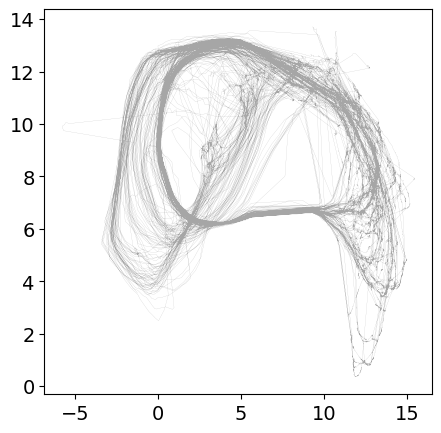

In [21]:
# Check how the UMAP projection looks
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(stoch_filenames))
trk_len_ode = int(len(embedding_all_prot)/len(stoch_filenames))

pos = 5

plt.plot(embedding_all_prot[pos*trk_len:(pos+1)*trk_len,0], embedding_all_prot[pos*trk_len:(pos+1)*trk_len,1], 
         lw=0.1, alpha=0.7, c='gray')



In [22]:
# Save the UMAP object
if GENERATE_UMAP:
    reducer_filename = Path(SAVE_DIR, 'UMAP', r_name)
    if not Path(SAVE_DIR,'UMAP').exists():
        os.mkdir(Path(SAVE_DIR,'UMAP'))
    if not reducer_filename.exists() or OVERWRITE:
        print(f'Saving reducer to {reducer_filename}')
        joblib.dump(reducer, reducer_filename)

Saving reducer to C:\Users\tysondr\ECM_mod_output\UMAP\reducer_win_0.1_0.1_4_0.5.sav


In [23]:
# We don't need the full runs from the ODE solutions for the UMAP, we can use a shortened segment of the run
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_ode_lyap)/len(ode_filenames)
sp = 1
for n in range(len(ode_filenames)):
    tmp = all_prot_ode_lyap[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [24]:
all_prot_tmp_ode_ab.shape

(20000, 720)

### Generate embedding of ODE solutions

In [25]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [26]:
# Save all the outputs
if SET_JPARAM:
    if  not Path(SAVE_DIR, f'all_embedding_ode_conds_psoparams_{sys_name}.sav').exists() or OVERWRITE:
        print(f'Saving UMAP embeddings for pso parameters on a {sys_name} system.')
        joblib.dump(embedding_all_prot_ode, Path(SAVE_DIR, f'all_embedding_ode_conds_psoparams_{sys_name}.sav'))
        joblib.dump(embedding_all_prot, Path(SAVE_DIR, f'all_embedding_stoch_conds_psoparams_{sys_name}.sav'))
        joblib.dump(all_prot_tmp, Path(SAVE_DIR, f'all_prot_stoch_conds_psoparams_{sys_name}.sav'))
        joblib.dump(all_time_tmp, Path(SAVE_DIR, f'all_time_tmp_{sys_name}_psoparams_from_0{output_from}.sav'))
        joblib.dump(all_time_at_tmp, Path(SAVE_DIR, f'all_time_at_tmp_{sys_name}_psoparams_from_0{output_from}.sav'))
else:
    if USE_ORIGINAL:
        if  not Path(SAVE_DIR, f'all_embedding_ode_conds_{sys_name}_orig.sav').exists() or OVERWRITE:
            print(f'Saving UMAP embeddings for original parameters on a {sys_name} system.')
            joblib.dump(embedding_all_prot_ode, Path(SAVE_DIR, f'all_embedding_ode_conds_{sys_name}_orig.sav'))
            joblib.dump(embedding_all_prot, Path(SAVE_DIR, f'all_embedding_stoch_conds_{sys_name}_orig.sav'))
            joblib.dump(all_prot_lyap, Path(SAVE_DIR, f'all_prot_stoch_conds_{sys_name}_orig.sav'))
            joblib.dump(all_time_lyap, Path(SAVE_DIR, f'all_time_tmp_{sys_name}_orig.sav'))
            joblib.dump(all_time_at_lyap, Path(SAVE_DIR, f'all_time_at_tmp_{sys_name}_orig.sav'))
    else:
        if  not Path(SAVE_DIR, f'all_embedding_ode_conds_{sys_name}_from_0{output_from}.sav').exists() or OVERWRITE:
            print(f'Saving UMAP embeddings using output from 0{output_from} on a {sys_name} system.')
            joblib.dump(embedding_all_prot_ode, Path(SAVE_DIR, f'all_embedding_ode_conds_{sys_name}_from_0{output_from}.sav'))
            joblib.dump(embedding_all_prot, Path(SAVE_DIR, f'all_embedding_stoch_conds_{sys_name}_from_0{output_from}.sav'))
            joblib.dump(all_prot_lyap, Path(SAVE_DIR, f'all_prot_stoch_conds_{sys_name}_from_0{output_from}.sav'))
            joblib.dump(all_time_lyap, Path(SAVE_DIR, f'all_time_tmp_{sys_name}_from_0{output_from}.sav'))
            joblib.dump(all_time_at_lyap, Path(SAVE_DIR, f'all_time_at_tmp_{sys_name}_from_0{output_from}.sav'))




Saving UMAP embeddings for original parameters on a win system.
